# Détection d'Anomalies

## Démarche
Trois approches :
- Statistiques, colonne par colonne (règle IQR, z-score) + contrôles de cohérence entre colonnes
- Multivariée (Isolation Forest, LOF) : une ligne peut être normale sur chaque variable prise seule, mais inhabituelle par la combinaison de ses valeurs
- Patterns fréquents (Apriori / FP-Growth) : quelles variables apparaissent ensemble plus souvent que le hasard

Une anomalie n'est pas forcément une erreur. Une valeur extrême peut être une vraie particularité du coeur, un artefact de mesure ou une erreur de saisie. Ce notebook sert à trouver des potentielles anomalies, pas à dire que ce sont des anomalies définitivement.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from scipy import stats
from scipy.signal import find_peaks
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

In [2]:
entities = pd.read_csv("registered_entities_cleaned.csv")
regulatory = pd.read_csv("regulatory_case_events_cleaned.csv")
access = pd.read_csv("site_access_case_events_cleaned.csv")

### Nettoyage + preparation
Il reste des problèmes pas clean dans les fichiers qui posent probleme quand j'ai voulu travailler dessus donc je reclean

Les tables sont des journaux d'événements : les colonnes brutes sont presque toutes catégorielles. Les colonnes numériques exploitables sont donc à faire : heure, délai depuis l'événement précédent du dossier, délai depuis l'ouverture, nombre d'événements du dossier

In [3]:
CASE = {"regulatory": ("cas"
                       "e_number", "regulatory_event_id"),
        "access": ("access_case_number", "access_event_id")}

# normalisation des résidus
for df in (regulatory, access):
    df["event_time"] = pd.to_datetime(df["event_time"])
    df["activity"] = df["activity"].str.strip().str.lower()
access["access_purpose"] = access["access_purpose"].str.split().str.join(" ")

# variables dérivées au niveau événement
def add_event_features(df, case_col, id_col):
    df = df.sort_values([case_col, "event_time", id_col]).reset_index(drop=True)
    g = df.groupby(case_col)["event_time"]
    df["hour"] = df["event_time"].dt.hour
    df["days_since_prev"] = g.diff().dt.total_seconds() / 86400
    df["days_since_open"] = (df["event_time"] - g.transform("min")).dt.total_seconds() / 86400
    df["n_events_case"] = g.transform("size")
    return df

regulatory = add_event_features(regulatory, *CASE["regulatory"])
access = add_event_features(access, *CASE["access"])
access["off_hours"] = (access["hour"] < 6) | (access["hour"] >= 18)

# entités : dates -> numérique
for c in ["registration_date", "last_filing_date"]:
    entities[c] = pd.to_datetime(entities[c])
entities["registration_year"] = entities["registration_date"].dt.year
entities["lifespan_years"] = (entities["last_filing_date"] - entities["registration_date"]).dt.days / 365.25

print(regulatory.shape, access.shape, entities.shape)

(232, 20) (412, 20) (24, 12)


## Anomalies statistiques
### Fonctions IQR et z-score

On applique les deux fonctions : si elles s'accordent, le signal est solide ; si elles divergent, la distribution est probablement asymétrique ou l'échantillon est petit.

`outlier_report` produit un tableau par colonne avec les bornes IQR et le nombre de valeurs hors bornes pour chaque méthode.

In [4]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), (low, high)

def zscore_outliers(s, thr=3.0):
    z = (s - s.mean()) / s.std(ddof=0)
    return z.abs() > thr, z

def outlier_report(df, cols, k=1.5, thr=3.0):
    rows = []
    for c in cols:
        m_iqr, (lo, hi) = iqr_outliers(df[c], k)
        m_z, _ = zscore_outliers(df[c], thr)
        rows.append({"colonne": c, "min": df[c].min(), "max": df[c].max(),
                     "borne_basse_IQR": lo, "borne_haute_IQR": hi,
                     "n_IQR": int(m_iqr.sum()), "n_zscore": int(m_z.sum())})
    return pd.DataFrame(rows).set_index("colonne")

précision
- Les tables ont peu de lignes (24 / 232 / 412) et des valeurs très répétitives (heures fixes, délais en paliers). Quand Q1 = Q3 (IQR = 0), toutes les valeurs différentes sont hors bornes : un grand `n_IQR` ne veut pas dire "erreur", il veut dire "valeur rare".
- Le z-score suppose une distribution proche de la normale mais ce n'est pas le cas ici. Il sert de second avis.
- Les entités sont étudiées avec `registration_year` et `lifespan_years` : on retrouve ici les entités dissoutes du XIXe/début XXe siècle repérées au nettoyage.

In [5]:
num_entities = ["registration_year", "lifespan_years"]
num_events = ["hour", "days_since_prev", "days_since_open", "n_events_case"]

print("=== registered_entities ===")
display(outlier_report(entities, num_entities))
print("=== regulatory_case_events ===")
display(outlier_report(regulatory, num_events))
print("=== site_access_case_events ===")
display(outlier_report(access, num_events))

=== registered_entities ===


,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
registration_year,1838.000000,2015.000000,1913.875000,2060.875000,3,1
lifespan_years,10.206708,56.205339,-17.298768,80.713552,0,0


=== regulatory_case_events ===


,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
hour,9.0,10.0,7.5,11.5,0,0
days_since_prev,1.0,20.0,-4.0,12.0,5,5
days_since_open,0.0,35.0,-13.0,27.0,5,5
n_events_case,5.0,7.0,3.5,7.5,0,0


=== site_access_case_events ===


,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
hour,3.000,18.000000,6.000000,14.000000,72,0
days_since_prev,0.375,10.375000,-1.708333,7.958333,22,0
days_since_open,0.000,34.083333,-10.500000,33.500000,18,0
n_events_case,4.000,10.000000,5.500000,9.500000,38,0


- `registered_entities` : seule `registration_year` ressort. `lifespan_years` est normale.
- `regulatory_case_events` : `hour` ne prend que 2 valeurs (9 h et 10 h), donc rien d'aberrant. Les 5 événements hors bornes sur `days_since_prev` et `days_since_open` sont repérés par l'IQR et le z-score : le signal est solide.
- `site_access_case_events` : sur `hour`, l'IQR signale 72 événements et le z-score aucun. La divergence est attendue : les heures sont en paliers (IQR étroit autour de 9–11 h). Ces 72 événements sont les démarrages d'accès à 17 h (36 cas, autres organisations) et, pour Horizon le démarrage à 18 h et la fin à 03 h. L'IQR seul ne sépare donc pas "17 h" de "18h -> 3h" : c'est l'approche multivariée qui le fera.
- Les 38 événements signalés sur `n_events_case` pour les accès ne sont pas à interpréter : la plupart des dossiers ont 6–8 événements, la borne est étroite, et une valeur rare n'est pas une anomalie.

In [6]:
# Entités hors bornes IQR sur l'année d'enregistrement
m, (lo, hi) = iqr_outliers(entities["registration_year"])
print(f"bornes IQR registration_year : {lo:.0f} – {hi:.0f}")
display(entities.loc[m, ["registration_number", "legal_name", "registered_entity_type", "registration_date",
                         "current_status", "last_filing_date", "lifespan_years"]])

bornes IQR registration_year : 1914 – 2061


,registration_number,legal_name,registered_entity_type,registration_date,current_status,last_filing_date,lifespan_years
14,REG-NDH-01015,Vann Maritime Advisory,consulting_company,1838-01-15,dissolved,1891-12-31,53.957563
15,REG-VLN-01016,Warden Medical Ventures,investment_company,1894-01-15,dissolved,1948-12-31,54.956879
17,REG-KNT-01018,Varlan Natural History Circle,research_institute,1883-01-15,dissolved,1920-12-31,37.957563


Les 3 sont des sociétés dissoutes dont la durée de vie est cohérente avec leurs dates de dépôt. Ce ne sont donc pas des erreurs de saisie mais des entités historiques.Il faudra essayer de voir dans les autres fichiers si une anomalie se présente (si une activité de ces entreprises a lieu après leur dissolution).

In [7]:
# Délais atypiques au sein d'un dossier (IQR sur days_since_prev), par fichier
for name, df, cc in [("regulatory", regulatory, "case_number"), ("access", access, "access_case_number")]:
    m, (lo, hi) = iqr_outliers(df["days_since_prev"])
    print(f"{name} : bornes IQR days_since_prev = [{lo:.1f}, {hi:.1f}] -> {int(m.sum())} événements")
    cols = [cc, "event_time", "activity", "days_since_prev", "outcome"]
    display(df.loc[m, cols].sort_values("days_since_prev", ascending=False).head(12))

regulatory : bornes IQR days_since_prev = [-4.0, 12.0] -> 5 événements


,case_number,event_time,activity,days_since_prev,outcome
28,REG-2018-0017,2018-05-09 10:00:00,case_closed,20.0,corrective action accepted
35,REG-2018-0029,2018-05-06 10:00:00,case_closed,20.0,corrective action accepted
149,REG-2022-0023,2022-12-01 10:00:00,case_closed,20.0,corrective action accepted
162,REG-2022-0035,2022-06-08 10:00:00,case_closed,20.0,corrective action accepted
180,REG-2023-0011,2023-10-26 10:00:00,case_closed,20.0,corrective action accepted


access : bornes IQR days_since_prev = [-1.7, 8.0] -> 22 événements


,access_case_number,event_time,activity,days_since_prev,outcome
51,ACC-2018-0001,2018-02-15 18:00:00,access_started,10.375,access commenced
59,ACC-2018-0002,2018-03-22 18:00:00,access_started,10.375,access commenced
67,ACC-2018-0003,2018-05-24 18:00:00,access_started,10.375,access commenced
102,ACC-2019-0004,2019-08-08 18:00:00,access_started,10.375,access commenced
117,ACC-2019-0006,2019-11-07 18:00:00,access_started,10.375,access commenced
109,ACC-2019-0005,2019-09-12 18:00:00,access_started,10.375,access commenced
401,ACC-2025-0017,2025-04-17 18:00:00,access_started,10.375,access commenced
299,ACC-2023-0013,2023-11-09 18:00:00,access_started,10.375,access commenced
160,ACC-2020-0007,2020-04-09 18:00:00,access_started,10.375,access commenced
168,ACC-2020-0008,2020-06-11 18:00:00,access_started,10.375,access commenced


- `regulatory_case_events` : les 5 événements sont tous des `case_closed` arrivés 20 jours après l'événement précédent, avec le même résultat (`corrective action accepted`). Ce sont les 5 dossiers `wildlife_inspection` de source routine (REG-2018-0017, 2018-0029, 2022-0023, 2022-0035, 2023-0011) : les seuls à aboutir à une action corrective acceptée, et les seuls à durer 35 jours.
- `site_access_case_events` : les 12 premiers événements sont tous des démarrages d'accès de Horizon à 18 h, 10,4 jours après l'événement précédent. Cet écart reste le même d'un dossier à l'autre donc c'est normal.

### Anomalies au niveau dossier

Un événement isolé est pas très utile. On va agrèger par dossier (nombre d'événements, durée totale) et on applique la même règle IQR.

In [8]:
def case_level_basic(df, case_col):
    g = df.groupby(case_col)["event_time"]
    return pd.DataFrame({"n_events": g.size(),
                         "duration_days": (g.max() - g.min()).dt.total_seconds() / 86400})

cases_reg_basic = case_level_basic(regulatory, "case_number")
cases_acc_basic = case_level_basic(access, "access_case_number")
for name, d in [("regulatory", cases_reg_basic), ("access", cases_acc_basic)]:
    print(name)
    display(outlier_report(d, ["n_events", "duration_days"]))
    print(d["duration_days"].value_counts().sort_index().to_string(), "\n")

regulatory


,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
n_events,5.0,7.0,3.5,7.5,0,0
duration_days,18.0,35.0,16.5,20.5,7,0


duration_days
18.0    29
19.0     4
22.0     2
35.0     5 

access


,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
n_events,4.0,10.000000,4.500,8.500000,5,0
duration_days,12.0,34.083333,-8.625,59.708333,0,0


duration_days
12.000000     6
17.000000    36
34.083333    18 



- `regulatory_case_events`: 29 dossiers durent 18 jours, 4 durent 19 jours, 2 durent 22 jours et 5 durent 35 jours. Les 7 dossiers hors bornes = les 5 dossiers de 35 jours + les 2 de 22 jours, qui sont deux dossiers "société civile" clos par `action recorded` (REG-2022-0007, site AVL-VEL ; REG-2025-0010, site KNT-SEN). Ce sont aussi des sites où Horizon a eu des accès.
- `site_access_case_events`: trois paliers seulement : 12 jours (6 dossiers, dont les refus), 17 jours (36 dossiers), 34 jours (18 dossiers). Les 18 dossiers de 34 jours sont exactement ceux de Horizon. Le z-score ne détecte rien parce qu'un groupe de 18 dossiers sur 60 pèse trop dans la moyenne et l'écart-type : le groupe est trop gros pour être extrême, mais il est bien distinct.
- Les 5 dossiers d'accès hors bornes sur `n_events` : les 2 dossiers à 4 événements (refus), les 2 à 9 et celui à 10 (les demandes Horizon renvoyées pour conditions supplémentaires, puis re-soumises).

### Contrôles de cohérence entre colonnes et entre fichiers

- chronologie : un événement ne doit pas être antérieur au précédent du même dossier
- chaînage des statuts : `previous_status` doit être égal au `new_status` de l'événement précédent
- numéros d'enregistrement présents dans les événements mais absents du registre `registered_entities`
- un même nom <=> un même numéro d'enregistrement
- événements datés avant l'enregistrement de l'entité ou après sa dissolution
- cohérence agence <=> catégorie de dossier : agence <=> préfixe du site (`AVL-`, `KNT-`, `TMB-`).

In [9]:
def check_chronology_and_chain(df, case_col, id_col):
    s = df.sort_values([case_col, id_col]).copy()
    s["prev_time"] = s.groupby(case_col)["event_time"].shift()
    s["prev_new_status"] = s.groupby(case_col)["new_status"].shift()
    back = s[s["prev_time"].notna() & (s["event_time"] < s["prev_time"])]
    chain = s[s["prev_new_status"].notna() & (s["prev_new_status"] != s["previous_status"])]
    return back, chain

for name, df in [("regulatory", regulatory), ("access", access)]:
    cc, ii = CASE[name]
    back, chain = check_chronology_and_chain(df, cc, ii)
    print(f"{name:11s} événements antérieurs au précédent : {len(back)} | ruptures de chaînage des statuts : {len(chain)}")

# numéros d'enregistrement hors registre
known = set(entities["registration_number"])
reg_orphans = (regulatory.dropna(subset=["subject_registration_number"])
               .loc[lambda d: ~d["subject_registration_number"].isin(known)]
               .groupby(["subject_registration_number", "subject_name"]).size().rename("n_events").reset_index())
acc_orphans = (access.dropna(subset=["requesting_registration_number"])
               .loc[lambda d: ~d["requesting_registration_number"].isin(known)]
               .groupby(["requesting_registration_number", "requesting_organization_name"]).size().rename("n_events").reset_index())
print(f"\nnuméros absents du registre : {len(reg_orphans)} (regulatory), {len(acc_orphans)} (access)")
print("numéros présents dans le registre ET dans les événements :",
      sorted(known & (set(regulatory['subject_registration_number'].dropna()) | set(access['requesting_registration_number'].dropna()))))
print("entités du registre jamais citées dans ces deux fichiers :", len(known - set(regulatory['subject_registration_number'].dropna())
      - set(access['requesting_registration_number'].dropna())), "/", len(known))
display(reg_orphans.head(8))

regulatory  événements antérieurs au précédent : 0 | ruptures de chaînage des statuts : 0
access      événements antérieurs au précédent : 0 | ruptures de chaînage des statuts : 0

numéros absents du registre : 13 (regulatory), 24 (access)
numéros présents dans le registre ET dans les événements : ['REG-AVL-01009', 'REG-AVL-01013', 'REG-NDH-01011', 'REG-TMB-01003', 'REG-VLN-01001', 'REG-VLN-01004', 'REG-VLN-01005', 'REG-VLN-01006', 'REG-VLN-01010']
entités du registre jamais citées dans ces deux fichiers : 15 / 24


,subject_registration_number,subject_name,n_events
0,REG-AVL-20007,Avelora Orchard Export Union,6
1,REG-AVL-20021,Velin Packaging Industries,12
2,REG-AVL-20030,Willow Regional Media Service,5
3,REG-AVL-20036,Riverstone Waste Management,13
4,REG-KNT-20006,Kintara Field Equipment Cooperative,6
5,REG-KNT-20014,Kestrel Conservation Services,6
6,REG-KNT-20032,Amber Storage and Transit,6
7,REG-NDH-20039,North Quay Biomedical Storage,6


- Aucune incohérence chronologique, aucune rupture dans la chaine de statuts, aucun événement hors de la période de vie d'une entité donc les journaux sont propres. Il n'y a pas d'anomalie ici.
- 15 entités sur 24 de `registered_entities` ne sont citées par aucun événement. Il faut probablement croiser avec d'autres fichiers.
- Horizon (REG-AVL-01013) est le seul demandeur du fichier `site_access_case_events` présent dans `registered_entities`.

In [10]:
# nom <-> numéro
for df, name_c, num_c in [(regulatory, "subject_name", "subject_registration_number"),
                          (access, "requesting_organization_name", "requesting_registration_number")]:
    multi = df.dropna(subset=[num_c]).groupby(name_c)[num_c].nunique()
    multi2 = df.dropna(subset=[num_c]).groupby(num_c)[name_c].nunique()
    print(num_c, "| noms avec plusieurs numéros :", int((multi > 1).sum()), "| numéros avec plusieurs noms :", int((multi2 > 1).sum()))

# organismes publics qui apparaissent sans numéro d'enregistrement
no_num = regulatory.loc[regulatory["subject_registration_number"].isna(), "subject_name"].value_counts()
print("\nsujets sans numéro (regulatory) :\n", no_num.to_string())
agencies = set(regulatory["agency_name"]) | set(access["authorizing_agency"])
print("\nsujets/demandeurs qui sont aussi des agences :",
      sorted((set(regulatory["subject_name"]) | set(access["requesting_organization_name"])) & agencies))

# événements hors de la période de vie de l'entité
ev = pd.concat([regulatory.rename(columns={"subject_registration_number": "reg"})[["reg", "event_time"]],
                access.rename(columns={"requesting_registration_number": "reg"})[["reg", "event_time"]]]).dropna()
ev = ev.merge(entities[["registration_number", "registration_date", "current_status", "last_filing_date"]],
              left_on="reg", right_on="registration_number")
bad = ev[(ev["event_time"] < ev["registration_date"]) |
         ((ev["current_status"] == "dissolved") & (ev["event_time"] > ev["last_filing_date"]))]
print("\névénements hors période de vie de l'entité :", len(bad))

subject_registration_number | noms avec plusieurs numéros : 0 | numéros avec plusieurs noms : 0
requesting_registration_number | noms avec plusieurs numéros : 0 | numéros avec plusieurs noms : 0

sujets sans numéro (regulatory) :
 subject_name
Avelora Agricultural Resilience Agency    25
Kintara Cave and Pollinator Authority     17
Office of the Kintara Chancellor          17
Tembara Biodiversity Service               7
Kintara Rural Transport Board              7

sujets/demandeurs qui sont aussi des agences : ['Avelora Agricultural Resilience Agency', 'Avelora Food Standards Office', 'Kintara Cave and Pollinator Authority', 'Nordhaven Maritime Safety Agency', 'Tembara Biodiversity Service', 'Tembara Customs Coordination Unit', 'Valenne Public Procurement Authority']

événements hors période de vie de l'entité : 0


Pas de doublon d'identité

In [11]:
# agence <-> catégorie : agence <-> site
display(pd.crosstab(regulatory.drop_duplicates("case_number")["case_category"],
                    regulatory.drop_duplicates("case_number")["agency_name"]))

pref = {"AVL": "Avelora Agricultural Resilience Agency", "KNT": "Kintara Cave and Pollinator Authority", "TMB": "Tembara Biodiversity Service"}
acc_cases = access.drop_duplicates("access_case_number")
mismatch = acc_cases[acc_cases["site_code"].str[:3].map(pref) != acc_cases["authorizing_agency"]]
print("dossiers d'accès où l'agence autorisante ne correspond pas au préfixe du site :", len(mismatch))

# Dossiers réglementaires de catégorie 'wildlife/medical' traités par une agence d'un autre domaine
display(regulatory.drop_duplicates("case_number")
        .groupby(["case_category", "agency_name"]).size().rename("n_cases").reset_index()
        .sort_values(["case_category", "n_cases"], ascending=[True, False]).head(40))

agency_name,Avelora Food Standards Office,Nordhaven Maritime Safety Agency,Orison Medical Audit Board,Tembara Customs Coordination Unit,Valenne Public Procurement Authority
case_category,,,,,
corporate_transparency,1,0,0,2,2
environmental_complaint,1,2,0,8,2
medical_audit,1,1,1,0,2
procurement_review,2,2,1,0,0
shipment_inspection,2,0,3,1,1
wildlife_inspection,0,0,1,2,2


dossiers d'accès où l'agence autorisante ne correspond pas au préfixe du site : 0


,case_category,agency_name,n_cases
1,corporate_transparency,Tembara Customs Coordination Unit,2
2,corporate_transparency,Valenne Public Procurement Authority,2
0,corporate_transparency,Avelora Food Standards Office,1
5,environmental_complaint,Tembara Customs Coordination Unit,8
4,environmental_complaint,Nordhaven Maritime Safety Agency,2
6,environmental_complaint,Valenne Public Procurement Authority,2
3,environmental_complaint,Avelora Food Standards Office,1
10,medical_audit,Valenne Public Procurement Authority,2
7,medical_audit,Avelora Food Standards Office,1
8,medical_audit,Nordhaven Maritime Safety Agency,1


Pas d'anomalie visible

## Anomalies multivariées : Isolation Forest et LOF

On passe au niveau dossier (40 dossiers réglementaires, 60 dossiers d'accès) : chaque événement d'un dossier hérite des mêmes attributs donc l'unité statistique réelle est le dossier, et les événements d'un même dossier ne sont pas indépendants.

Choix de méthode :
- `RobustScaler` (médiane / IQR) plutôt que la standardisation classique, pour ne pas laisser les valeurs extrêmes écraser l'échelle
- Isolation Forest répété sur plusieurs graines et LOF avec un voisinage petit (`n_neighbors` = ~8)
- on n'inclut pas l'identité de l'organisation ni sa présence dans `registered_entities` dans les variables : on cherche à savoir si certains dossiers sortent du lot par leur comportement seul
- score final = moyenne des rangs des deux méthodes

Si un comportement bizarre a lieu dans beaucoup de dossiers, il forme lui-même un amas dense. L'Isolation Forest le détecte encore (il est séparable des autres), mais LOF peut dire que c'est normal car ses voisins sont semblables. Un écart entre les deux méthodes peut être une information.

In [12]:
def build_access_case_features(a):
    a = a.copy()
    g = a.groupby("access_case_number")
    start = a[a.activity == "access_started"].set_index("access_case_number")["event_time"]
    end = a[a.activity == "access_completed"].set_index("access_case_number")["event_time"]
    f = pd.DataFrame({
        "n_events": g.size(),
        "duration_days": g["event_time"].agg(lambda x: (x.max() - x.min()).total_seconds() / 86400),
        "n_persons": g["authorized_person_name"].nunique(),
        "n_off_hours": g["off_hours"].sum(),
        "n_security_review": g["activity"].agg(lambda x: (x == "security_review").sum()),
        "n_resubmissions": g["new_status"].agg(lambda x: (x == "resubmitted").sum()),
        "was_denied_or_returned": g["new_status"].agg(lambda x: x.isin(["denied", "returned"]).any()).astype(int),
        "conf_level": g["confidentiality_class"].first().map({"standard": 0, "confidential": 1, "restricted": 2}),
    })
    f["field_hours"] = ((end - start).dt.total_seconds() / 3600).reindex(f.index).fillna(0)
    f["max_gap_days"] = g["days_since_prev"].max().fillna(0)
    cat = g[["authorizing_agency", "access_purpose", "equipment_category"]].first()
    return f, cat

def build_regulatory_case_features(r):
    g = r.groupby("case_number")
    f = pd.DataFrame({
        "n_events": g.size(),
        "duration_days": g["event_time"].agg(lambda x: (x.max() - x.min()).total_seconds() / 86400),
        "max_gap_days": g["days_since_prev"].max().fillna(0),
        "has_site": g["related_site_code"].agg(lambda x: x.notna().any()).astype(int),
        "has_public_ref": g["public_reference"].agg(lambda x: x.notna().any()).astype(int),
        "has_inspection": g["activity"].agg(lambda x: (x == "inspection_completed").any()).astype(int),
        "has_finding": g["activity"].agg(lambda x: x.isin(["finding_issued", "referral_recorded"]).any()).astype(int),
        "n_external_material": g["outcome"].agg(lambda x: x.str.startswith("material received from", na=False).sum()),
        "civil_society": g["initiating_source"].agg(lambda x: (x == "civil society referral").any()).astype(int),
    })
    cat = g[["case_category", "agency_name"]].first()
    return f, cat

acc_num, acc_cat = build_access_case_features(access)
reg_num, reg_cat = build_regulatory_case_features(regulatory)
print(acc_num.shape, reg_num.shape)
display(acc_num.describe().T[["mean", "min", "max"]])

(60, 10) (40, 9)


,mean,min,max
n_events,6.866667,4.0,10.000000
duration_days,21.625000,12.0,34.083333
n_persons,6.283333,4.0,9.000000
n_off_hours,0.600000,0.0,2.000000
n_security_review,0.200000,0.0,1.000000
n_resubmissions,0.050000,0.0,1.000000
was_denied_or_returned,0.150000,0.0,1.000000
conf_level,0.583333,0.0,2.000000
field_hours,13.500000,0.0,18.000000
max_gap_days,6.512500,4.0,10.375000


In [13]:
def multivariate_scores(num, cat, seeds=range(10), n_neighbors=8, contamination=0.1):
    X = pd.concat([num, pd.get_dummies(cat, dtype=float)], axis=1)
    Xs = RobustScaler().fit_transform(X)
    # Isolation Forest : moyenne sur plusieurs graines (n petit => instable)
    iso = np.mean([-IsolationForest(n_estimators=300, contamination=contamination, random_state=s)
                   .fit(Xs).score_samples(Xs) for s in seeds], axis=0)
    # LOF
    lof_model = LocalOutlierFactor(n_neighbors=min(n_neighbors, len(X) - 1), contamination=contamination)
    lof_model.fit_predict(Xs)
    lof = -lof_model.negative_outlier_factor_
    out = pd.DataFrame({"iforest": iso, "lof": lof}, index=num.index)
    out["rank_iforest"] = out["iforest"].rank(ascending=False)
    out["rank_lof"] = out["lof"].rank(ascending=False)
    out["rank_mean"] = out[["rank_iforest", "rank_lof"]].mean(axis=1)
    return out.sort_values("rank_mean"), Xs

acc_scores, acc_X = multivariate_scores(acc_num, acc_cat)
reg_scores, reg_X = multivariate_scores(reg_num, reg_cat)

# Contexte lisible à côté des scores
acc_ctx = access.drop_duplicates("access_case_number").set_index("access_case_number")[
    ["site_code", "requesting_organization_name", "access_purpose", "confidentiality_class"]]
reg_ctx = regulatory.drop_duplicates("case_number").set_index("case_number")[
    ["case_category", "initiating_source", "agency_name", "subject_name", "related_site_code"]]

print("Dossiers d'accès : 20 plus atypiques")
display(acc_scores.join(acc_ctx).head(20).round(2))
print("Dossiers réglementaires : 15 plus atypiques")
display(reg_scores.join(reg_ctx).head(15).round(2))

Dossiers d'accès : 20 plus atypiques


,iforest,lof,rank_iforest,rank_lof,rank_mean,site_code,requesting_organization_name,access_purpose,confidentiality_class
access_case_number,,,,,,,,,
ACC-2023-0013,0.61,1.39,1.0,2.0,1.5,AVL-VEL,Horizon Field Research Cooperative,habitat survey and sample documentation,confidential
ACC-2018-0040,0.57,1.35,4.0,3.0,3.5,AVL-ARU,Dune Agricultural Machinery,emergency equipment recovery,restricted
ACC-2018-0019,0.55,1.42,6.0,1.0,3.5,KNT-CYP,Interregional Procurement Cooperative,emergency equipment recovery,standard
ACC-2022-0033,0.56,1.25,5.0,6.0,5.5,KNT-UJJ,Kestrel Conservation Services,sensor maintenance,standard
ACC-2023-0026,0.54,1.24,8.0,7.0,7.5,KNT-CHP,Tembara Coastal Research Trust,emergency equipment recovery,standard
ACC-2024-0015,0.58,1.05,2.0,14.0,8.0,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,standard
ACC-2021-0010,0.57,1.03,3.0,17.0,10.0,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,restricted
ACC-2024-0014,0.53,1.07,10.0,13.0,11.5,KNT-KES,Horizon Field Research Cooperative,night wildlife monitoring programme,restricted
ACC-2023-0047,0.51,1.25,19.5,4.5,12.0,AVL-KAR,Tembara Customs Coordination Unit,routine monitoring visit,standard


Dossiers réglementaires : 15 plus atypiques


,iforest,lof,rank_iforest,rank_lof,rank_mean,case_category,initiating_source,agency_name,subject_name,related_site_code
case_number,,,,,,,,,,
REG-2018-0029,0.56,3.57,4.5,1.5,3.0,wildlife_inspection,routine referral,Valenne Public Procurement Authority,Velin Packaging Industries,KNT-XAC
REG-2018-0017,0.62,3.12,1.0,5.0,3.0,wildlife_inspection,routine referral,Orison Medical Audit Board,Avelora Agricultural Resilience Agency,KNT-VLB
REG-2022-0035,0.56,3.57,4.5,1.5,3.0,wildlife_inspection,routine referral,Valenne Public Procurement Authority,Riverstone Waste Management,AVL-HTY
REG-2022-0023,0.56,3.56,6.5,3.5,5.0,wildlife_inspection,routine referral,Tembara Customs Coordination Unit,Office of the Kintara Chancellor,KNT-QWU
REG-2023-0011,0.56,3.56,6.5,3.5,5.0,wildlife_inspection,routine referral,Tembara Customs Coordination Unit,Kintara Rural Transport Board,KNT-CYP
REG-2024-0009,0.60,1.00,2.0,9.0,5.5,shipment_inspection,civil society referral,Orison Medical Audit Board,Meridian BioLogistics,AVL-MAR
REG-2023-0026,0.54,1.00,8.0,22.0,15.0,corporate_transparency,routine referral,Avelora Food Standards Office,Cedar Public Affairs Advisory,NaN
REG-2023-0008,0.49,1.03,26.0,6.0,16.0,environmental_complaint,civil society referral,Tembara Customs Coordination Unit,Meridian BioLogistics,KNT-KES
REG-2019-0012,0.53,1.00,10.0,22.0,16.0,procurement_review,routine referral,Orison Medical Audit Board,Auric Medical Supplies,NaN


In [14]:
# dossiers signalés (top10 % par Isolation Forest) -> profil de l'organisation demandeuse
top_n = int(round(0.3 * len(acc_scores)))
flag = acc_scores.sort_values("rank_iforest").head(top_n).join(acc_ctx)
print(f"Top {top_n} dossiers d'accès (Isolation Forest) par organisation demandeuse :")
print(flag["requesting_organization_name"].value_counts().head(5).to_string())

top_r = 10
flag_r = reg_scores.sort_values("rank_iforest").head(top_r).join(reg_ctx)
print(f"\nTop {top_r} dossiers réglementaires (Isolation Forest) par source :")
print(flag_r["initiating_source"].value_counts().to_string())

Top 18 dossiers d'accès (Isolation Forest) par organisation demandeuse :
requesting_organization_name
Horizon Field Research Cooperative       14
Dune Agricultural Machinery               1
Kestrel Conservation Services             1
Interregional Procurement Cooperative     1
Tembara Coastal Research Trust            1

Top 10 dossiers réglementaires (Isolation Forest) par source :
initiating_source
routine referral          7
civil society referral    3


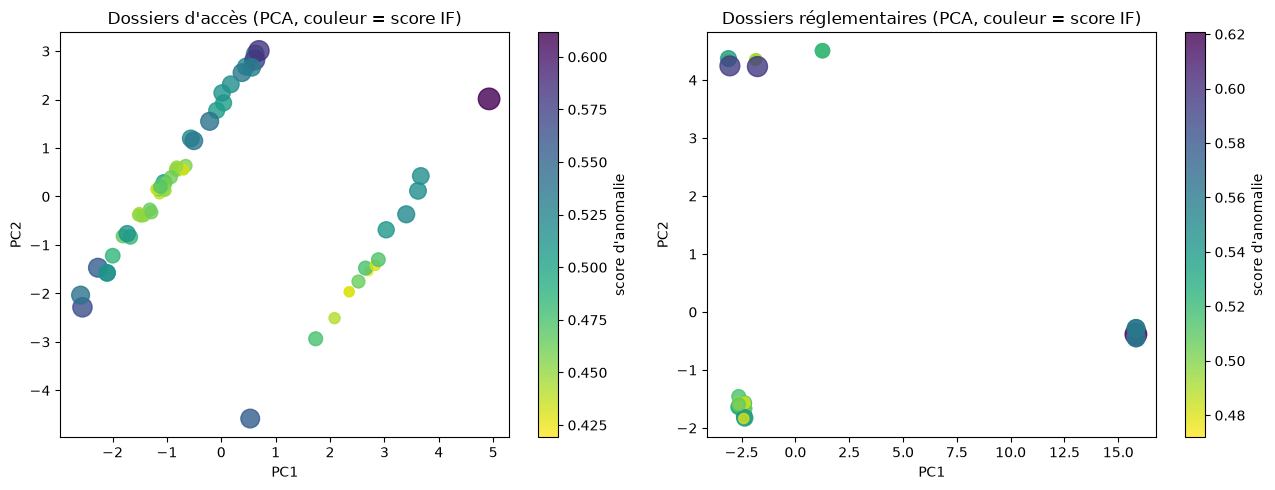

In [15]:
# Projection PCA pour visualiser (2D) : taille/couleur = score Isolation Forest
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, X, sc, ctx, key) in zip(axes, [
        ("Dossiers d'accès", acc_X, acc_scores, acc_ctx, "requesting_organization_name"),
        ("Dossiers réglementaires", reg_X, reg_scores, reg_ctx, "initiating_source")]):
    idx = (acc_num if title.startswith("Dossiers d'accès") else reg_num).index
    P = PCA(n_components=2, random_state=0).fit_transform(X)
    s = sc.loc[idx, "iforest"].values
    sca = ax.scatter(P[:, 0], P[:, 1], c=s, cmap="viridis_r", s=40 + 200 * (s - s.min()) / (s.max() - s.min()), alpha=.8)
    ax.set_title(title + " (PCA, couleur = score IF)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    plt.colorbar(sca, ax=ax, label="score d'anomalie")
plt.tight_layout(); plt.show()

- `site_access_case_events`: 14 des 18 dossiers du top Isolation Forest sont Horizon alors qu'on n'a pas donné le nom de l'organisation au modèle. Les 3 plus atypiques sont les demandes Horizon renvoyées pour conditions supplémentaires (ACC-2023-0013, ACC-2024-0015, ACC-2021-0010). LOF classe autrement : il place surtout en tête des refus d'organisations isolées (ACC-2018-0019, 2018-0040, 2022-0033, 2023-0026, ainsi qu'ACC-2023-0013 de Horizon en 2eme position), cas individuellement inhabituels, alors que Horizon forme un amas de 18 dossiers semblables. LOF repère des cas isolés, l'Isolation Forest repère un comportement collectif distinct.
- Les 6 refus (`access denied`) concernent d'autres organisations que Horizon.
- `regulatory_case_events` : les 5 dossiers `wildlife_inspection` de routine dominent les deux classements (7 événements, 35 jours, action corrective). REG-2024-0009 est 2eme pour l'Isolation Forest.

## Règles d'association

On veut voir quelles modalités apparaissent ensemble plus souvent que le hasard (lift > 1). On travaille sur des variables catégorielles one-hot.

- les colonnes strictement redondantes (ex. `initiating_source` <=> `assigned_unit` : mêmes 2 groupes) sont retirées automatiquement, sinon on obtient des règles à confiance 100 %
- `activity` et `outcome` sont presques pareils (chaque activité a presque tjr le meme résultat) : leurs combinaisons sont lues dans un tableau croisé, et les règles qui contiennent les deux sont écartées pour laisser voir les liens avec le contexte (source, agence, catégorie, confidentialité...)
- avec 40 / 60 dossiers, un support de 5% ne représente que 2–3 dossiers : les règles sont des pistes, pas des preuves
- FP-Growth et Apriori donnent les mêmes itemsets : on vérifie l'égalité.

In [16]:
def drop_redundant_columns(df, cols):
    keep = []
    for c in cols:
        twin = next((k for k in keep if df[c].nunique() == df[k].nunique() == len(df[[c, k]].drop_duplicates())), None)
        if twin:
            print(f"colonne redondante retirée : {c} (partition identique à {twin})")
        else:
            keep.append(c)
    return keep

def mine_rules(df, cols, min_support=0.05, min_conf=0.8, min_lift=1.5, max_len=3, exclude_pair=None):
    cols = drop_redundant_columns(df, cols)
    basket = pd.get_dummies(df[cols].astype(str), prefix_sep="=").astype(bool)
    fp = fpgrowth(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    ap = apriori(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    assert set(fp["itemsets"]) == set(ap["itemsets"]), "FP-Growth et Apriori divergent"
    try:
        rules = association_rules(fp, num_itemsets=len(basket), metric="confidence", min_threshold=min_conf)
    except TypeError: # anciennes versions de mlxtend
        rules = association_rules(fp, metric="confidence", min_threshold=min_conf)
    rules = rules[rules["lift"] >= min_lift].copy()
    if exclude_pair:
        a, b = exclude_pair
        both = rules.apply(lambda r: any(i.startswith(a + "=") for i in r["antecedents"] | r["consequents"]) and
                                     any(i.startswith(b + "=") for i in r["antecedents"] | r["consequents"]), axis=1)
        rules = rules[~both].copy()
    rules["n_rows"] = (rules["support"] * len(basket)).round().astype(int)
    for c in ["antecedents", "consequents"]:
        rules[c] = rules[c].apply(lambda s: " & ".join(sorted(s)))
    keep_cols = ["antecedents", "consequents", "n_rows", "support", "confidence", "lift"]
    return rules[keep_cols].sort_values(["lift", "confidence", "n_rows"], ascending=False).reset_index(drop=True), len(fp)

for name, df in [("regulatory", regulatory), ("access", access)]:
    ct = pd.crosstab(df["activity"], df["outcome"])
    multi = ct[(ct > 0).sum(axis=1) > 1]
    print(f"{name} : activités à résultats multiples")
    for act, row in multi.iterrows():
        print(f"  {act}: " + " | ".join(f"{o} ({n})" for o, n in row[row > 0].items()))

rules_reg, n_fp = mine_rules(regulatory, ["activity", "outcome", "case_category", "initiating_source", "agency_name", "assigned_unit"],
                             min_support=0.04, min_conf=0.8, min_lift=1.5, exclude_pair=("activity", "outcome"))
print(f"{n_fp} itemsets fréquents ; {len(rules_reg)} règles retenues")
display(rules_reg.head(25).round(2))

regulatory : activités à résultats multiples
  case_closed: action recorded (2) | case closed (4) | case closed after review (4) | case closed without further action (25) | corrective action accepted (5)
  evidence_received: material received from Common Ground Climate Forum (2) | material received from Earth Ledger Project (3) | material received from Lantern Investigative Bureau (2) | material received from Pollinator Justice Network (2) | material received from Threshold Earth Observatory (1) | records received (30)
  finding_issued: corrective action requested (5) | monitoring recommendation issued (4) | temporary restriction issued (2)
access : activités à résultats multiples
  access_completed: field work completed (18) | work completed (36)
  authorization_denied: access denied (6) | additional conditions required (3)
  request_submitted: conditions updated (3) | request logged (60)
colonne redondante retirée : assigned_unit (partition identique à initiating_source)
125 itemsets

,antecedents,consequents,n_rows,support,confidence,lift
0,case_category=shipment_inspection & initiating...,agency_name=Orison Medical Audit Board,14,0.06,1.0,6.11
1,agency_name=Orison Medical Audit Board & initi...,case_category=shipment_inspection,14,0.06,1.0,5.27
2,agency_name=Tembara Customs Coordination Unit ...,initiating_source=civil society referral,48,0.21,1.0,3.74
3,agency_name=Tembara Customs Coordination Unit ...,case_category=environmental_complaint,48,0.21,1.0,3.18
4,case_category=environmental_complaint & initia...,agency_name=Tembara Customs Coordination Unit,48,0.21,1.0,2.97


- `regulatory_case_events` : 5 règles à confiance 100 %, qui disent deux choses : tout événement d'une plainte environnementale traitée par `Tembara Customs Coordination Unit` vient de la société civile (lift 3,7), toute inspection d'expédition d'origine "société civile" est confiée à `Orison Medical Audit Board` (lift 6,1).
- Tableau croisé activité \* résultat : les dossiers "société civile" sont ouverts par la réception de matériel venant de 5 organisations (Lantern Investigative Bureau, Earth Ledger Project, Pollinator Justice Network, Common Ground Climate Forum, Threshold Earth Observatory), toutes présentes dans `registered_entities` : 10 dossiers, 10 `material received from...`. Les dossiers de routine reçoivent `records received` (30 cas). À la clôture, les dossiers de routine finissent presque tous (25 sur 30) en `closed without further action`, jamais les dossiers "société civile" (`closed`, `closed after review`, `action recorded`).
- `site_access_case_evennts` : la règle la plus forte relie `restricted` + objet "acoustic monitoring and equipment maintenance" à du matériel de stockage frigorifique (25 événements, lift 7,4), un profil qu'on retrouve chez Horizon. Les règles avec `confidentiality_class=standard` décrivent le fonctionnement courant des autres organisations (objet <=> matériel <=> agence). Elles servent de point de comparaison.

In [17]:
# règles dont la conséquence est la source 'civil society referral'
mask = rules_reg["consequents"].str.contains("initiating_source=civil society referral")
display(rules_reg[mask].head(15).round(2))

rules_acc, n_fp = mine_rules(access, ["activity", "outcome", "confidentiality_class", "equipment_category",
                                      "access_purpose", "authorizing_agency"],
                             min_support=0.04, min_conf=0.8, min_lift=1.5, exclude_pair=("activity", "outcome"))
print(f"{n_fp} itemsets fréquents, {len(rules_acc)} règles retenues")
display(rules_acc.head(25).round(2))

,antecedents,consequents,n_rows,support,confidence,lift
2,agency_name=Tembara Customs Coordination Unit ...,initiating_source=civil society referral,48,0.21,1.0,3.74


198 itemsets fréquents, 17 règles retenues


,antecedents,consequents,n_rows,support,confidence,lift
0,access_purpose=acoustic monitoring and equipme...,equipment_category=portable monitoring and col...,25,0.06,1.00,7.36
1,confidentiality_class=restricted & equipment_c...,access_purpose=acoustic monitoring and equipme...,25,0.06,1.00,5.64
2,authorizing_agency=Avelora Agricultural Resili...,access_purpose=acoustic monitoring and equipme...,17,0.04,1.00,5.64
3,confidentiality_class=standard & equipment_cat...,access_purpose=acoustic monitoring and equipme...,17,0.04,1.00,5.64
4,access_purpose=habitat survey and sample docum...,equipment_category=protective field equipment,18,0.04,1.00,3.89
5,access_purpose=emergency equipment recovery & ...,authorizing_agency=Kintara Cave and Pollinator...,22,0.05,1.00,2.37
6,access_purpose=emergency equipment recovery & ...,authorizing_agency=Kintara Cave and Pollinator...,19,0.05,1.00,2.37
7,access_purpose=sensor maintenance & equipment_...,authorizing_agency=Kintara Cave and Pollinator...,18,0.04,1.00,2.37
8,access_purpose=sensor maintenance & authorizin...,confidentiality_class=standard,30,0.07,1.00,1.79
9,access_purpose=habitat restoration assessment ...,confidentiality_class=standard,28,0.07,1.00,1.79


In [18]:
# comportement du dossier access
acc_basket = acc_cat.join(acc_ctx[["confidentiality_class"]]).copy()
acc_basket["night_work"] = np.where(acc_num["n_off_hours"] > 0, "yes", "no")
acc_basket["security_review"] = np.where(acc_num["n_security_review"] > 0, "yes", "no")
acc_basket["resubmitted"] = np.where(acc_num["n_resubmissions"] > 0, "yes", "no")
acc_basket["long_case_34d"] = np.where(acc_num["duration_days"] >= 30, "yes", "no")
acc_basket["denied"] = np.where(acc_num["was_denied_or_returned"] > 0, "yes", "no")
acc_basket["in_registry"] = np.where(access.drop_duplicates("access_case_number").set_index("access_case_number")["requesting_registration_number"].reindex(acc_basket.index).isin(known), "yes", "no")

rules_acc_case, n_fp = mine_rules(acc_basket, list(acc_basket.columns), min_support=0.10, min_conf=0.9, min_lift=1.5, max_len=3)
print(f"{n_fp} itemsets fréquents, {len(rules_acc_case)} règles retenues")
display(rules_acc_case.head(25).round(2))

colonne redondante retirée : long_case_34d (partition identique à night_work)
colonne redondante retirée : in_registry (partition identique à night_work)
277 itemsets fréquents, 18 règles retenues


,antecedents,consequents,n_rows,support,confidence,lift
0,security_review=yes,denied=no & night_work=yes,11,0.18,0.92,3.67
1,security_review=yes,night_work=yes & resubmitted=no,11,0.18,0.92,3.67
2,security_review=yes,night_work=yes,12,0.20,1.00,3.33
3,denied=no & security_review=yes,night_work=yes,11,0.18,1.00,3.33
4,resubmitted=no & security_review=yes,night_work=yes,11,0.18,1.00,3.33
5,access_purpose=acoustic monitoring and equipme...,night_work=yes,9,0.15,1.00,3.33
6,access_purpose=acoustic monitoring and equipme...,night_work=yes,7,0.12,1.00,3.33
7,access_purpose=acoustic monitoring and equipme...,night_work=yes,7,0.12,1.00,3.33
8,equipment_category=portable monitoring and col...,night_work=yes,7,0.12,1.00,3.33
9,access_purpose=acoustic monitoring and equipme...,night_work=yes,6,0.10,1.00,3.33


- Le code a retiré `long_case_34d` et `in_registry` comme redondantes de `night_work` : les trois critères "accès de nuit", "dossier de 34 jours" et "demandeur présent dans le registre" désignent exactement les mêmes 18 dossiers (ceux de Horizon).
- `security_review=yes -> night_work=yes` à 100 % : les 12 dossiers avec revue sécurité sont tous Horizon, aucune autre organisation n'en a (12 sur 18 dossiers Horizon concernés). La revue sécurité est donc un trait propre à ce groupe.
- Le matériel "portable monitoring and cold-storage equipment" et l'objet "acoustic monitoring and equipment maintenance" vont aussi systématiquement avec l'accès de nuit. Inversement, "camera equipment" ou "habitat restoration assessment" vont avec les accès de jour sans refus ni revue sécurité (lift 1,5–1,7, règle faible).

## Bilan

Les journaux sont cohérents : pas de retour en arrière dans le temps, pas de rupture de statuts, pas d'événement hors de la vie d'une entité, une agence autorisante toujours conforme au site. Les anomalies ne pourraient être que des comportements. Les 3 entités dissoutes du XIXe siècle sont atypiques mais cohérentes en interne si on ne se base que sur ces 3 fichiers csv.

Un groupe d'accès qui se distingue sur toutes les variables : Horizon Field Research Cooperative (18 dossiers, 2018–2025). Accès de 18 h à 03 h (les autres : 17 h -> 11 h le lendemain), dossiers de 34 jours (contre 12 ou 17), revue sécurité dans 12 dossiers sur 18 (aucune ailleurs), 14 dossiers sur 18 `confidential` ou `restricted`, matériel de stockage frigorifique. Trois demandes ont été renvoyées pour conditions supplémentaires puis re-soumises, ce qui est unique dans le fichier. Ce groupe est le seul demandeur du fichier d'accès à figurer dans `registered_entities`. C'est un mode opératoire répété (2 à 3 dossiers par an) pas une anomalie isolée.

Les dossiers "société civile" sont traités différemment des dossiers de routine. Dix dossiers, tous ouverts par du matériel transmis par 5 organisations de `registered_entities`, horodatés 09:00 (10:00 pour la routine), 8 sur 10 à `Tembara Customs Coordination Unit` et 2 à `Orison Medical Audit Board`, jamais clos "sans suite" (contre 25 dossiers de routine sur 30). Ils ne sont pas des valeurs extrêmes, mais ils forment un groupe à part par leurs attributs. Leur cible est toujours soit une agence, soit Meridian BioLogistics (en regardant directement le csv) : 6 dossiers visent une agence et 4 visent Meridian BioLogistics. Dans les 6 cas, l'agence visée est celle qui autorise l'accès de Horizon sur le même site (`Avelora...` à AVL-MAR/AVL-VEL, `Kintara...` à KNT-KES/KNT-SEN, `Tembara...` à TMB-NAC).

- Les 5 dossiers `wildlife_inspection` de routine (35 jours, action corrective acceptée) sont le seul autre groupe atypique du fichier réglementaire. Ils sont confiés à des agences sans lien évident avec la faune.
- Les 6 refus d'accès concernent de petites organisations isolées (dont `Tembara Customs Coordination Unit`, ACC-2023-0047) : ce sont des cas individuels que LOF met en tête.
- Les numéros d'enregistrement `2xxxx` (hors `registered_entities`) forment une population séparée à croiser avec les autres fichiers de l'équipe.